# Demo Script

## 1-D and 2-D Detector Simulations and Analytic Reconstructions

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import os
import time

import numpy as np
import matplotlib.pyplot as plt

import jax
import jax.numpy as jnp
import optax

from xpc_ct.phantoms import resample_smooth_2D, make_circle_cluster_phantom
from xpc_ct.materials import make_material
from xpc_ct import forward, phase_retrieval, tomography

from xpc_ct.plotting import *   # plot style preferences

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


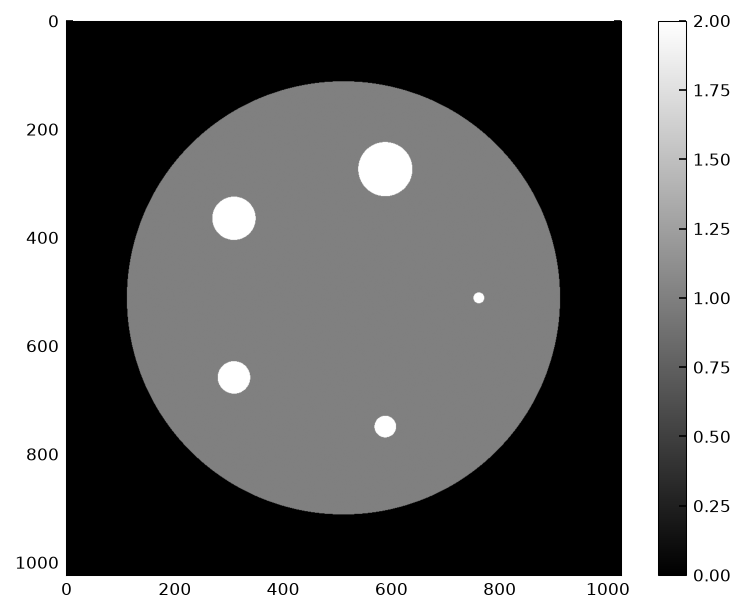

In [4]:
iq_phantom = make_circle_cluster_phantom()
plt.imshow(iq_phantom)
plt.colorbar()
plt.show()

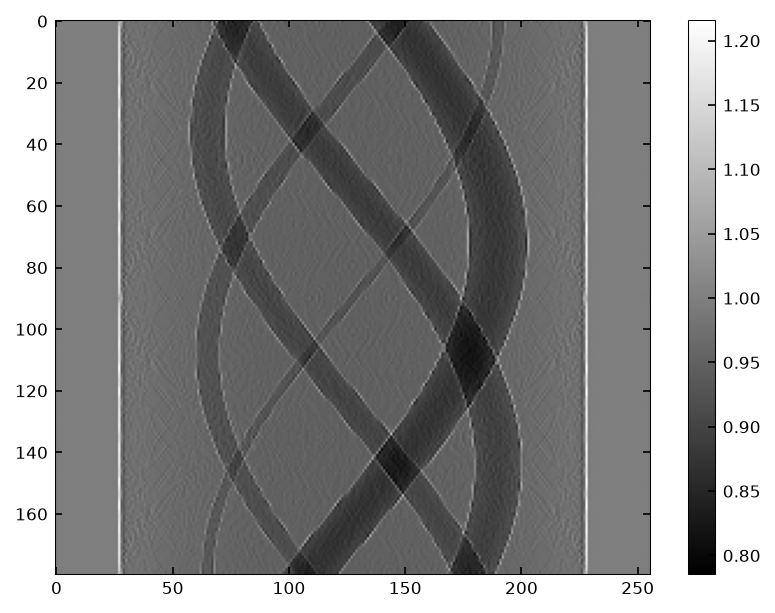

In [5]:
# A 1-D detector simulation


matnames = ['air', 'water', 'bone']
material_maps = jnp.stack([
    iq_phantom == m for m in range(len(matnames))
]).astype(jnp.float32)

pars = dict(
    I0_per_um2 = 1,
    propdist =   10e-2,
    energies =   jnp.array([20.0]),
    thetas =     jnp.linspace(0, jnp.pi, 180, endpoint=False),
    Nx =         iq_phantom.shape[0],
    dx =         1.3e-6,
    upx =        4,
    material_names = tuple(matnames),
)
sim = forward.ProjApproxPBI(**pars)
rescale_factor = sim.I0_per_um2 * (1e6 * sim.det_dx)**2/pars['upx']  #the data seems to be need to be rescaled by pars['upx'] relative to old code. Not clear why
data_1d = sim.apply({}, material_maps).squeeze() / rescale_factor

plt.imshow(data_1d, aspect='auto', cmap='gray')
plt.colorbar()
plt.show()

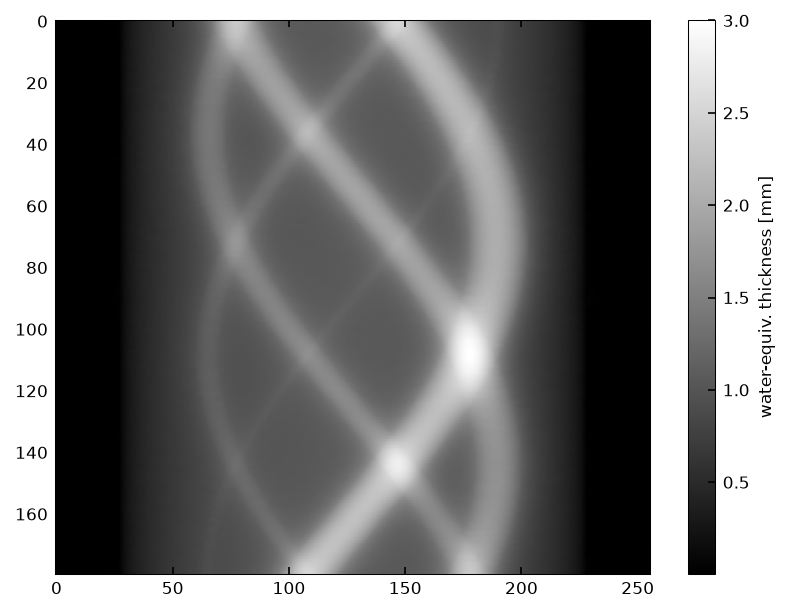

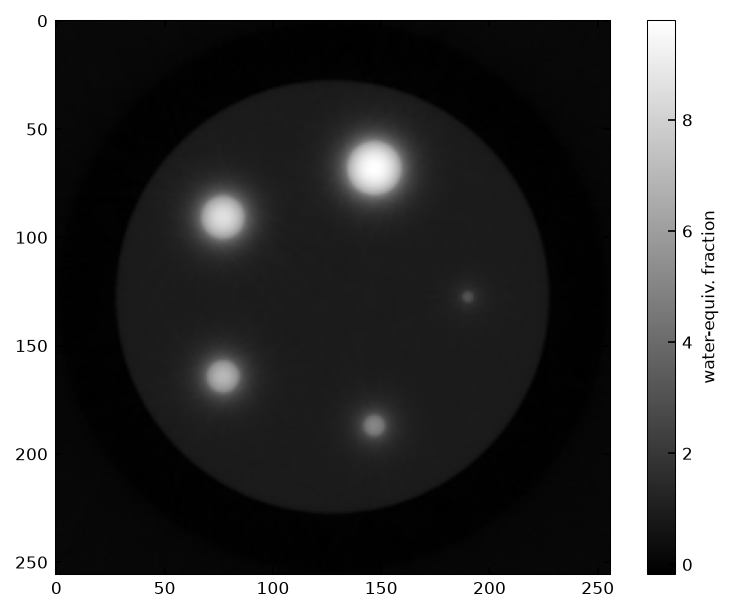

In [6]:
# Paganin phase retrieval (sinogram domain)

sino_paganin = phase_retrieval.paganin_pr(
    data_1d[...,None], sim.energies[0], sim.propdist, sim.det_dx
).squeeze()

plt.imshow(sino_paganin * 1e3, aspect='auto', cmap='gray')
plt.colorbar(label='water-equiv. thickness [mm]')
plt.show()

############################################################################
# CT reconstruction on the paganin-PR sinogram

N_matrix = 256
FOV = sim.fov_x #fov_x=fov_z for 1-D. fov_y=None
s = sim.det_dx

recon_paganin = tomography.get_recon(sino_paganin, N_matrix, FOV, s, sim.thetas)

plt.imshow(recon_paganin)
plt.colorbar(label='water-equiv. fraction')
plt.show()

IndexError: Too many indices: array is 2-dimensional, but 3 were indexed

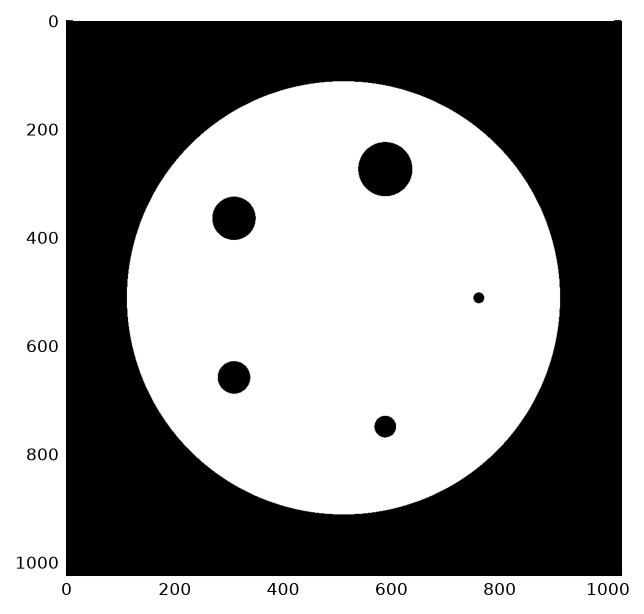

In [8]:
# A 3-D example

#Set up a simple 3-D phantom
material_maps.shape
#plt.imshow(material_maps[1,:,:])
material_maps_vol = jnp.repeat(material_maps[:,:,np.newaxis,:],64,axis=2)
plt.imshow(material_maps_vol[1,:,0,:])


matnames = ['air', 'water', 'bone']
material_maps = jnp.stack([
    iq_phantom == m for m in range(len(matnames))
]).astype(jnp.float32)

pars = dict(
    I0_per_um2 = 1,
    propdist =   10e-2,
    energies =   jnp.array([20.0]),
    thetas =     jnp.linspace(0, jnp.pi, 180, endpoint=False),
    Nx =         iq_phantom.shape[0],
    Ny =         material_maps_vol.shape[2],
    dx =         1.3e-6,
    dy =         1.3e-6,
    upx =        4,
    upy =        4,
    material_names = tuple(matnames),
)
sim = forward.ProjApproxPBI(**pars)
rescale_factor = sim.I0_per_um2 * (1e6 * sim.det_dx)**2
raw_data = sim.apply({}, material_maps_vol).squeeze() 
data = raw_data / rescale_factor
plt.imshow(data[:,5,:], aspect='auto', cmap='gray')
plt.colorbar()
plt.show()

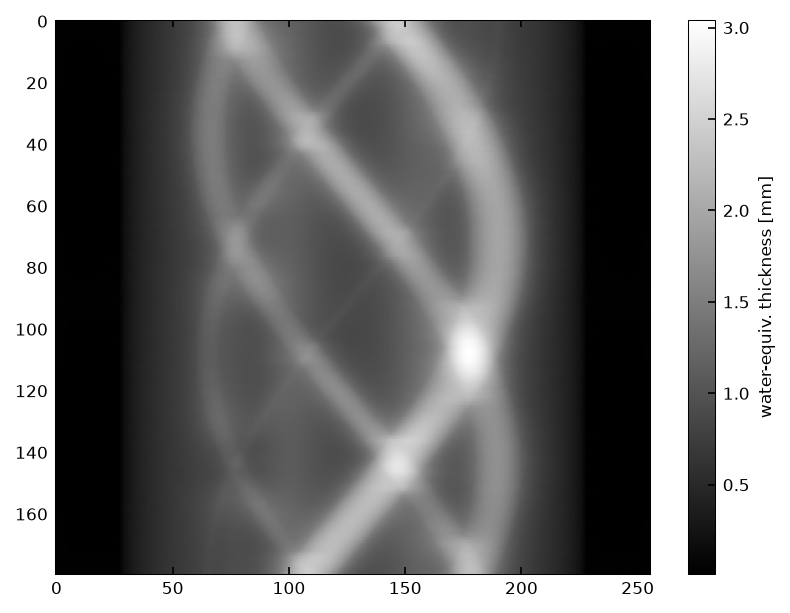

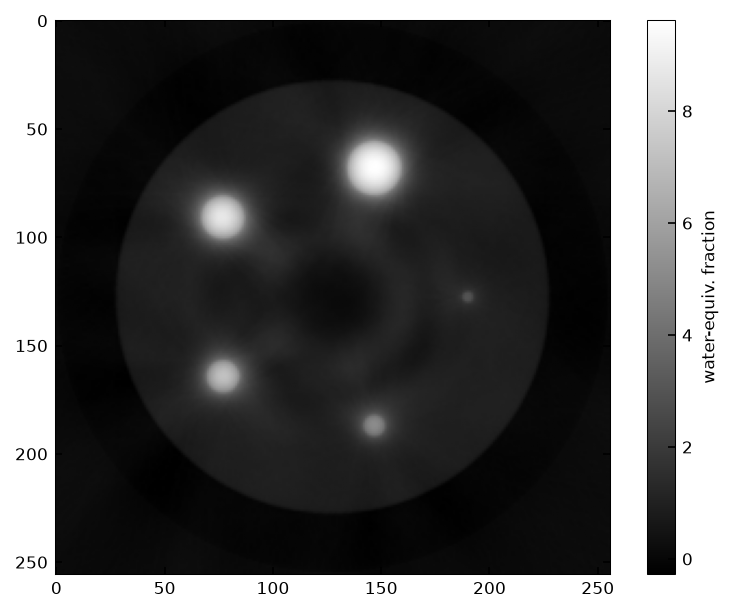

In [26]:
#3-D phase retrieval
sino_paganin = phase_retrieval.paganin_pr(
    data[...], sim.energies[0], sim.propdist, sim.det_dx
).squeeze()

plt.imshow(sino_paganin[:,8,:] * 1e3, aspect='auto', cmap='gray')
plt.colorbar(label='water-equiv. thickness [mm]')
plt.show()

N_matrix = 256
FOV = sim.fov_x #fov_x=fov_z for 1-D. fov_y=None
s = sim.det_dx

recon_paganin = tomography.get_recon(sino_paganin[:,8,:], N_matrix, FOV, s, sim.thetas)

plt.imshow(recon_paganin)
plt.colorbar(label='water-equiv. fraction')
plt.show()

R = 130.0 mm, detector dx = 5.2 um


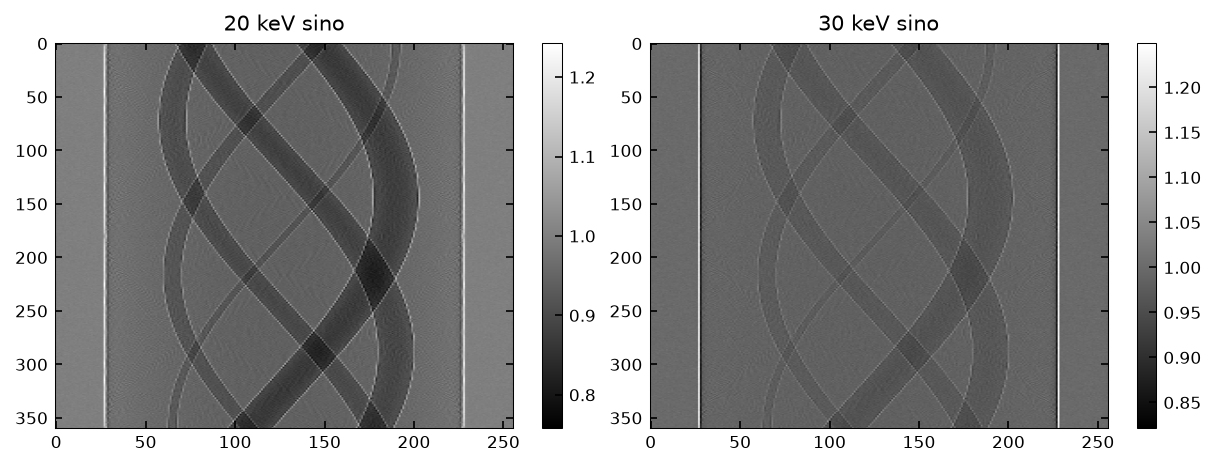

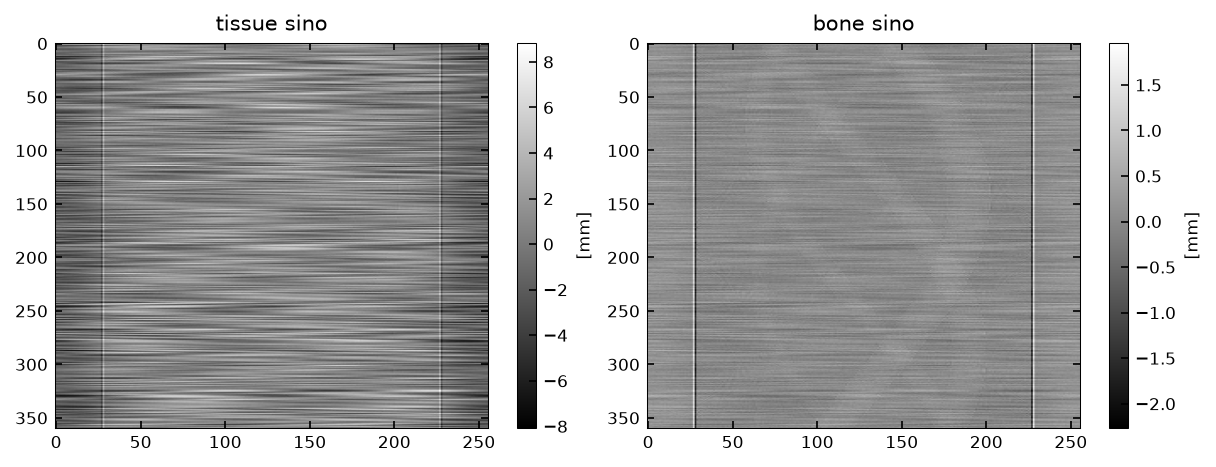

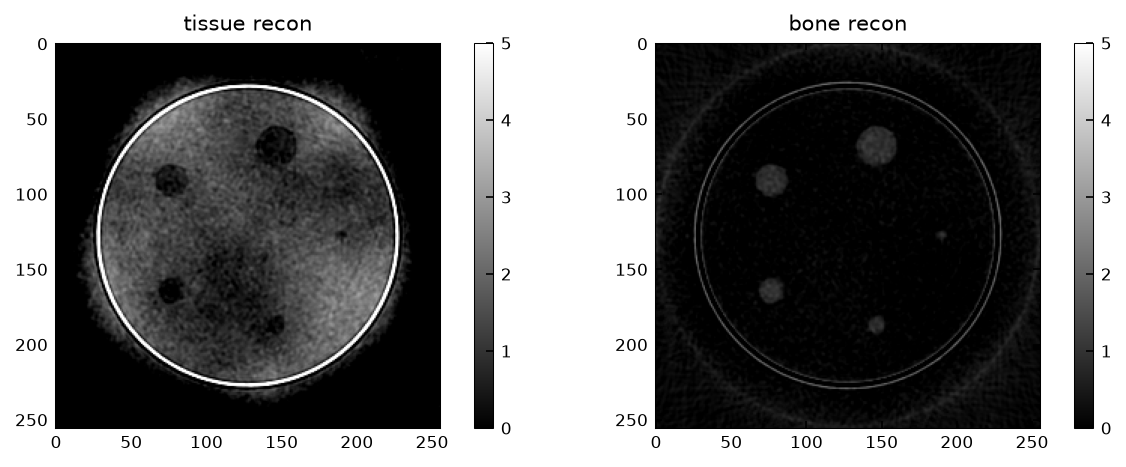

In [30]:
#1-D mat decomp example

de_pars = dict(
    I0_per_um2 = 1,
    propdist =   130e-3,
    energies =   jnp.array([20.0, 30.0]),
    thetas =     jnp.linspace(0, jnp.pi, 360, endpoint=False),
    Nx =         iq_phantom.shape[0],
    dx =         1.3e-6,
    upx =        4,
    material_names = tuple(['air', 'tissue', 'bone']),
)

de_sim = forward.ProjApproxPBI(**de_pars)
de_data_counts = de_sim.apply({}, material_maps)

# noise
de_data_counts = forward.add_poisson_noise(de_data_counts, key=jax.random.PRNGKey(3), scale=1e4)

# normalize 
I0 = de_sim.I0_per_um2 * (1e6 * de_sim.det_dx)**2/de_pars['upx']  # rescale factor for normalizing
de_data = de_data_counts / I0

print(f'R = {de_sim.propdist*1e3:.1f} mm, detector dx = {de_sim.det_dx*1e6:.1f} um')

fig, ax = plt.subplots(1, 2, figsize=[8,3], layout='constrained')
for i in range(2):
    ax[i].set_title(f'{de_sim.energies[i]:.0f} keV sino')
    m = ax[i].imshow(de_data[i], aspect='auto', cmap='gray')
    fig.colorbar(m, ax=ax[i])
plt.show()


###################################################################
# 2. Material decomposition (sinograms)

Tissue = make_material('tissue')
Bone = make_material('bone')
basis_materials = [Tissue, Bone]

mat_sinos = phase_retrieval.tie_matdecomp(
    de_data[...,None],
    de_sim.energies,
    de_sim.propdist,
    de_sim.det_dx,
    basis_materials
).squeeze()

fig, ax = plt.subplots(1, 2, figsize=[8,3], layout='constrained')
for i in range(2):
    ax[i].set_title(f'{basis_materials[i].name} sino')
    m = ax[i].imshow(1e3*mat_sinos[i], aspect='auto', cmap='gray')
    fig.colorbar(m, ax=ax[i], label='[mm]')
plt.show()


###################################################################
# 3. CT reconstruction 

N_matrix = 256
FOV = de_sim.fov_x
s = de_sim.det_dx
angles = de_sim.thetas

de_recons = [
    tomography.get_recon(
        mat_sinos[i], N_matrix, FOV, s, angles, ramp_window='hann', ramp_cutoff=0.9) 
    for i in range(2)
]

fig, ax = plt.subplots(1, 2, figsize=[8,3], layout='constrained')
for i in range(2):
    ax[i].set_title(f'{basis_materials[i].name} recon')
    m = ax[i].imshow(de_recons[i], aspect='equal', cmap='gray', vmin=0, vmax=5)
    fig.colorbar(m, ax=ax[i])
plt.show()

## Iterative Recon

In [54]:
# Set up

def keep_iterating(loss_hist, max_hist=1000, w=10, thresh=1e-3):
    if len(loss_hist) > max_hist:
        return False
    elif len(loss_hist) > w:
        return (np.abs(loss_hist[-1] - loss_hist[-w]) >= thresh)
    return True

def overlap_penalty(recons, axes=(0,1)):
    im1, im2 = recons[axes[0]], recons[axes[0]]
    return jnp.mean(im1 * im2)

def clip_constraint(recons):
    return jnp.clip(recons, 0.0, 2.0)

def mask_constraint(recons, mask):
    return jnp.where(mask, recons, 0.0)

def plot_recons(opt_recons, gt_arr, loss_history):
    fig, ax = plt.subplots(1, 5, figsize=[16, 3], dpi=100, layout='constrained')

    # recon panels
    for i in range(2):
        ax[i].set_title(f'mat {i+1} recon')
        m = ax[i].imshow(opt_recons[i], aspect='equal', cmap='viridis')
        fig.colorbar(m, ax=ax[i])

    # recon - ground truth panels
    for i in range(2):
        err = opt_recons[i] - gt_arr[i]
        vmax = np.max(np.abs(np.asarray(err)))

        ax[i + 2].set_title(f'mat {i+1} error')
        m = ax[i + 2].imshow(err, aspect='equal', cmap='bwr', vmin=-vmax, vmax=vmax)
        fig.colorbar(m, ax=ax[i + 2])

    # loss panel
    ax[4].set_title('loss')
    ax[4].plot(loss_history, '.-')
    ax[4].set_xlabel('iteration')
    ax[4].set_yscale('log')

    plt.show()

In [50]:
%%time

########################################################
### Copy and change pars for optimization forward model

opt_pars = de_pars.copy()  # make sure to use de_data later

# Use the downsampled detector/object grid for the recon model
mat1_arr = material_maps[1, ::de_sim.upx, ::de_sim.upx]
mat2_arr = material_maps[2, ::de_sim.upx, ::de_sim.upx]
gt_arr = jnp.stack([mat1_arr, mat2_arr])
finite_support = jnp.array(1 - material_maps[0,::de_sim.upx,::de_sim.upx], dtype=bool)

opt_pars['Nx'] = gt_arr.shape[-1]
opt_pars['dx'] = de_sim.det_dx
opt_pars['upx'] = 1
opt_pars['material_names'] = ['tissue', 'bone']


########################################################
### Set up the optimizer

lrate = 5e-3
r_weight = 0.1

optimizer = optax.chain(
    optax.clip_by_global_norm(1.0),
    optax.adam(lrate),
)

opt_recons = 0.5 * jnp.array(de_recons)  # init guess
opt_state = optimizer.init(opt_recons)

recon_model = forward.ProjApproxPBI(**opt_pars)
recon_fwd = jax.jit(
    lambda material_maps: recon_model.apply({}, material_maps)
)


def loss_fn(recons, data):
    y = recon_fwd(recons)
    fidelity = jnp.mean((y - data)**2)  
    reg = r_weight * overlap_penalty(recons)
    loss = fidelity + reg
    aux = {
        'fidelity': fidelity,
        'reg': reg,
        'loss': loss,
    }
    return loss, aux

    
@jax.jit
def train_step(recons, opt_state, data):
    (loss, aux), grads = jax.value_and_grad(loss_fn, has_aux=True)(recons, data)

    updates, opt_state = optimizer.update(grads, opt_state, recons)
    recons = optax.apply_updates(recons, updates)

    recons = clip_constraint(recons)
    recons = mask_constraint(recons, finite_support)

    return recons, opt_state, loss, aux


CPU times: user 5.41 ms, sys: 4.92 ms, total: 10.3 ms
Wall time: 5.19 ms


iter 0: loss = 7.7979e-01, fidelity = 7.4292e-01, reg = 3.6870e-02


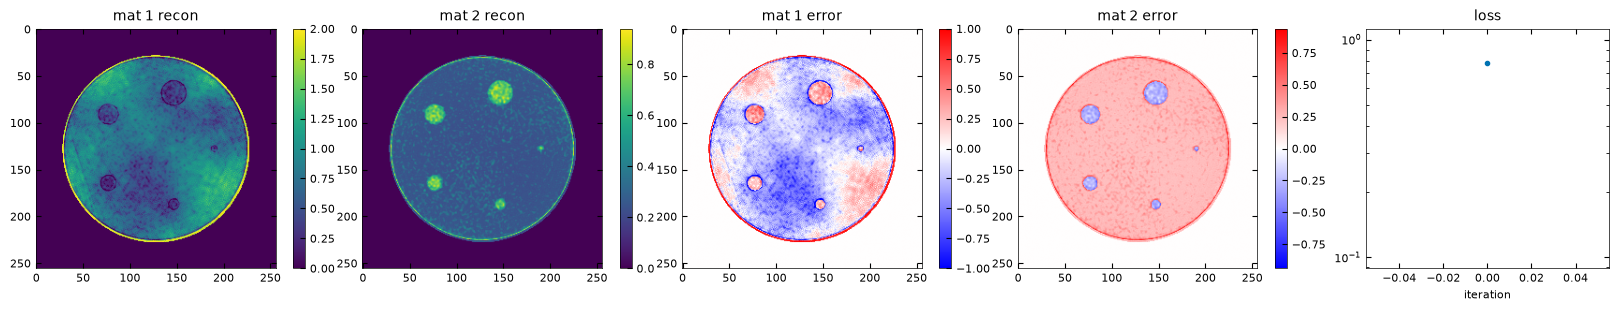

iter 20: loss = 7.2774e-01, fidelity = 6.9139e-01, reg = 3.6345e-02


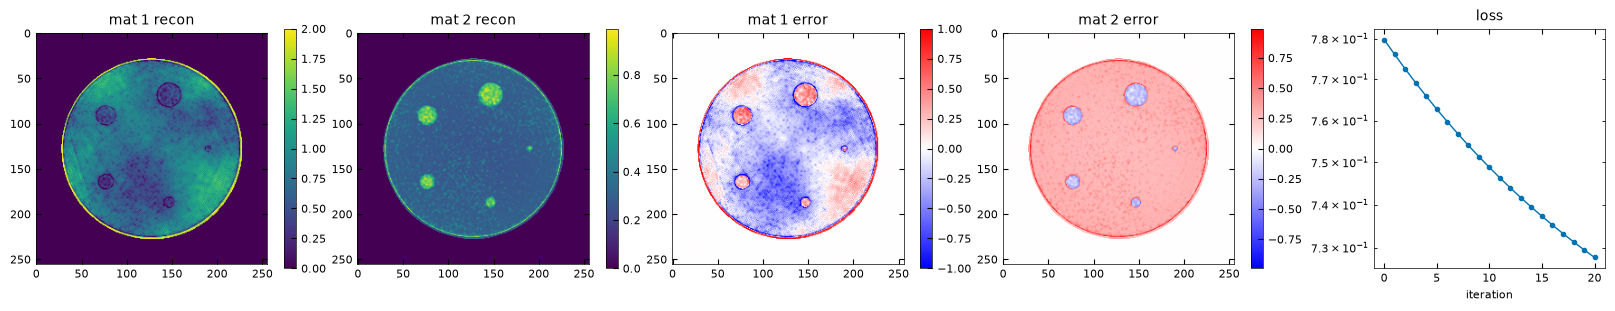

iter 40: loss = 7.0222e-01, fidelity = 6.6756e-01, reg = 3.4661e-02


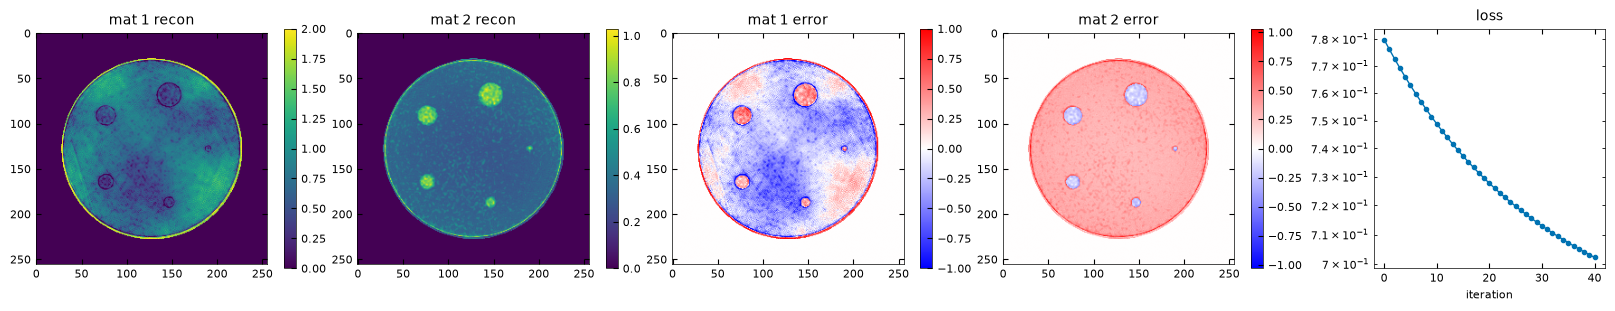

iter 60: loss = 6.8699e-01, fidelity = 6.5462e-01, reg = 3.2370e-02


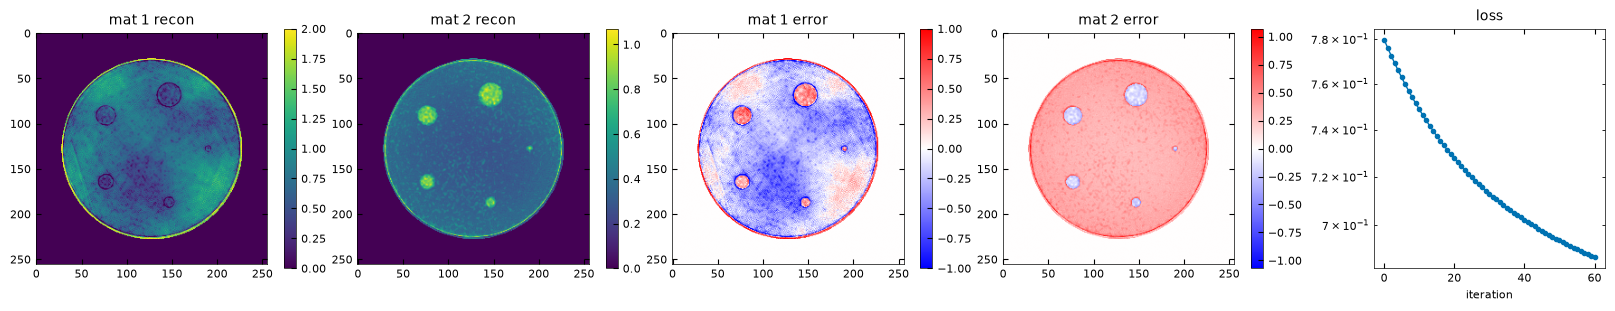

iter 80: loss = 6.7608e-01, fidelity = 6.4623e-01, reg = 2.9851e-02


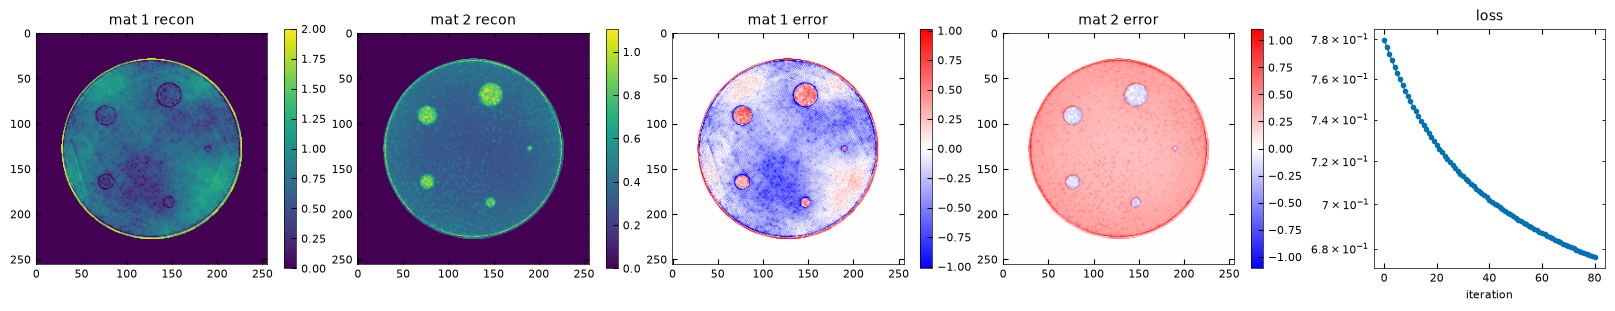

iter 100: loss = 6.6716e-01, fidelity = 6.3984e-01, reg = 2.7320e-02


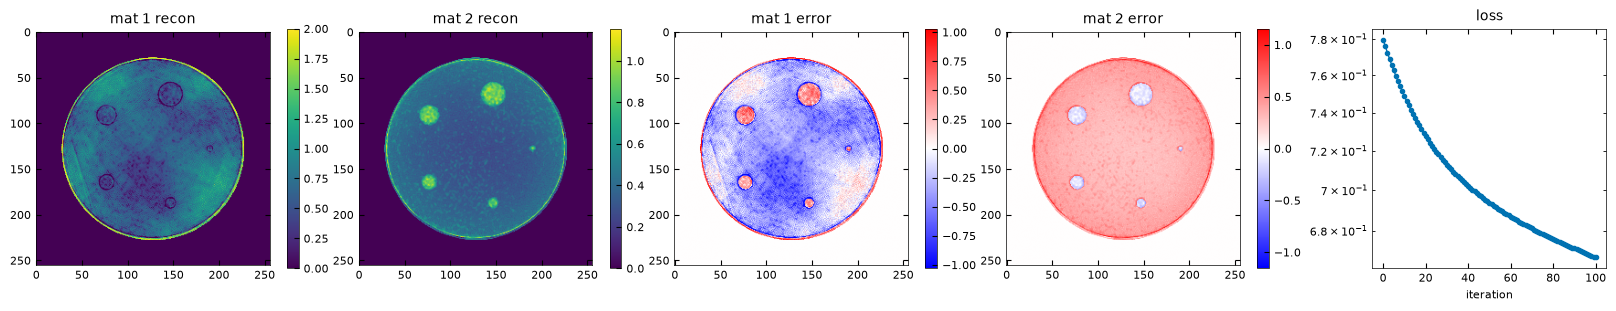

iter 120: loss = 6.5952e-01, fidelity = 6.3462e-01, reg = 2.4898e-02


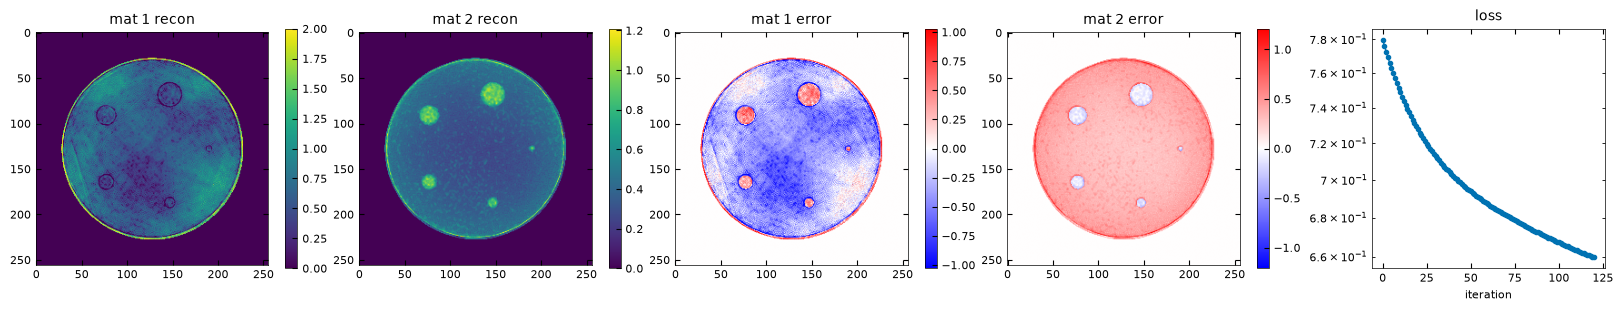

iter 140: loss = 6.5316e-01, fidelity = 6.3053e-01, reg = 2.2630e-02


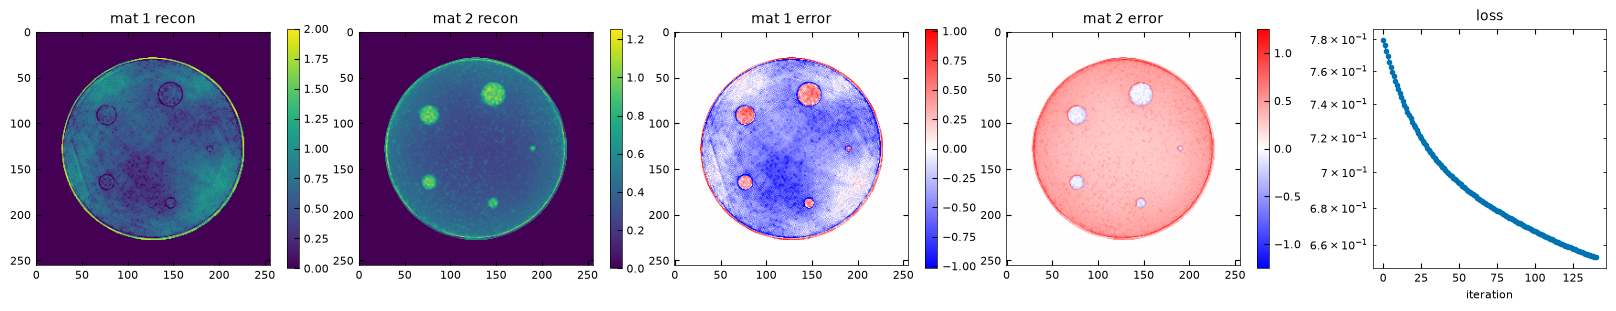

In [ ]:

########################################################
### Run
loss_history = []

it = 0
while keep_iterating(loss_history, max_hist=500, w=5, thresh=1e-3):

    opt_recons, opt_state, loss, aux = train_step(opt_recons, opt_state, de_data_counts)  # make sure data is correct!!
    loss_history.append(float(aux['loss']))

    if (it % 20 == 0):
        print(
            f'iter {it}: '
            f'loss = {float(aux["loss"]):.4e}, '
            f'fidelity = {float(aux["fidelity"]):.4e}, '
            f'reg = {float(aux["reg"]):.4e}'
        )

        plot_recons(opt_recons, gt_arr, loss_history)
    it += 1

print(f'final iter: {it}')